# V2.1 — Leakage-Controlled 1–7 Day Berlin Temperature Forecasting

## Purpose
The central experimental question is:

> **How do persistence baselines, Prophet, Bidirectional LSTM, and Transformer models perform for direct 1–7 day ahead daily mean temperature forecasting in Berlin when all models are evaluated under the same information constraints?**

### Major methodological changes from V1

1. **Direct 7-day forecasting:** the neural networks predict all seven future temperatures simultaneously instead of being trained only for one-step prediction and then recursively rolled forward.
2. **Strict chronological splitting:** train / validation / test are separated in time.
3. **No scaling leakage:** scalers are fitted only on data available before the relevant evaluation period.
4. **No future meteorological regressors:** Prophet is evaluated without using future humidity, radiation, wind, or precipitation that would not be known at forecast time.
5. **Naive baselines:** persistence and weekly seasonal-naive forecasts are included.
6. **MAPE removed:** temperature can be zero or negative, so MAPE is not an appropriate primary metric.
7. **Horizon-specific metrics:** MAE, RMSE, R², sMAPE and MASE are reported separately for horizons 1–7.
8. **Rolling-origin final evaluation:** several 7-day forecast origins are evaluated using only information available at each origin.
9. **Hyperparameter tuning:** deep-learning tuning uses the validation period only; the test period is never used for model selection.
10. **Reproducibility:** fixed random seed, explicit dates, saved configuration and saved result tables.

> **Important:** Run the notebook from top to bottom. Do not change the test period after seeing test results.

> **V2.1 change:** the final test evaluation uses weekly, non-overlapping forecast origins rather than only six widely spaced origins, and reports origin-level uncertainty.


# 1. Experimental Design

### Data

- Location: Berlin, Germany
- Coordinates: 52.52°N, 13.405°E
- Source: Open-Meteo historical API / ERA5
- Daily observations
- Default history: 2021-01-01 through 2026-08-31
- Target: daily mean 2-m air temperature (`temp_mean`)

### Candidate models

**Baselines**
- Persistence: tomorrow and the following six days equal the last observed temperature.
- Weekly seasonal naive: each future day uses the temperature seven days earlier.

**Statistical**
- Prophet using historical target values and calendar seasonality only.

**Deep learning**
- Bidirectional LSTM
- Transformer encoder

### Forecasting strategy

All neural models use:

**30 observed days → 7 future daily mean temperatures**

No model receives future observed weather variables during evaluation.

### Final evaluation

The final test uses multiple forecast origins. At each origin:

1. Only observations available up to that date are used.
2. Deep-learning scalers are fitted using only observations available up to that date.
3. Deep-learning models are trained using observations available up to that date and the previously selected hyperparameters.
4. Prophet is fitted only to observations available up to that date.
5. Each model predicts the next seven days.
6. Predictions are compared against the actual next seven days.

This is the core V2 evaluation protocol.

In [1]:
# 2. Installation
# Recommended: create the environment once outside this notebook.
# For uv users, run in the terminal:
#   uv venv
#   uv pip install numpy pandas matplotlib scikit-learn tensorflow keras-tuner prophet requests
#
# If the required packages are already installed, this cell can be skipped.


In [2]:
# 3. Imports and reproducibility

import os
import json
import random
import logging
import warnings
from datetime import date, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras import Model, Sequential
from tensorflow.keras.layers import (
    Input, Dense, Dropout, LSTM, Bidirectional,
    LayerNormalization, MultiHeadAttention,
    GlobalAveragePooling1D, Add
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

import keras_tuner as kt
from prophet import Prophet

warnings.filterwarnings("ignore")
logging.getLogger("prophet").setLevel(logging.WARNING)
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)


Importing plotly failed. Interactive plots will not work.


TensorFlow: 2.21.0
NumPy: 2.5.3
Pandas: 3.0.6


In [3]:
# 4. Configuration

LATITUDE = 52.52
LONGITUDE = 13.405
CITY = "Berlin"

# Keep these dates fixed for the final thesis run.
START_DATE = "2021-01-01"
END_DATE = "2026-08-31"

LOOKBACK = 30
HORIZON = 7

TRAIN_RATIO = 0.70
VALIDATION_RATIO = 0.15
TEST_RATIO = 0.15

# Weekly, non-overlapping forecast origins for the final test evaluation.
# This gives substantially more test origins than the original 6-origin V2 run.
TEST_ORIGIN_STEP_DAYS = 7

# Tuning controls
RUN_TUNING = True
LSTM_MAX_TRIALS = 8
TRANSFORMER_MAX_TRIALS = 8
TUNER_MAX_EPOCHS = 30

# Final rolling evaluation can be computationally expensive.
RUN_ROLLING_EVALUATION = True

# Optional analyses
RUN_FEATURE_ABLATION = False
RUN_LOOKBACK_ABLATION = False
RUN_LIVE_FORECAST = False

METEO_FEATURES = [
    "temp_max",
    "temp_min",
    "temp_mean",
    "precipitation",
    "wind_speed_max",
    "radiation",
    "evapotranspiration",
    "humidity_max",
    "humidity_min",
    "humidity_mean",
]

TARGET = "temp_mean"

print(json.dumps({
    "city": CITY,
    "coordinates": [LATITUDE, LONGITUDE],
    "start_date": START_DATE,
    "end_date": END_DATE,
    "lookback": LOOKBACK,
    "forecast_horizon": HORIZON,
    "train_ratio": TRAIN_RATIO,
    "validation_ratio": VALIDATION_RATIO,
    "test_ratio": TEST_RATIO,
    "test_origin_step_days": TEST_ORIGIN_STEP_DAYS,
}, indent=2))


{
  "city": "Berlin",
  "coordinates": [
    52.52,
    13.405
  ],
  "start_date": "2021-01-01",
  "end_date": "2026-08-31",
  "lookback": 30,
  "forecast_horizon": 7,
  "train_ratio": 0.7,
  "validation_ratio": 0.15,
  "test_ratio": 0.15,
  "test_origin_step_days": 7
}


# 5. Data Collection

The historical period is explicitly fixed so that the final thesis results can be reproduced.

The API data are treated as historical meteorological observations/reanalysis data. The forecasting experiment itself does not use future meteorological covariates.

In [4]:
def fetch_open_meteo_history(
    latitude=LATITUDE,
    longitude=LONGITUDE,
    start_date=START_DATE,
    end_date=END_DATE,
):
    url = "https://archive-api.open-meteo.com/v1/archive"

    params = {
        "latitude": latitude,
        "longitude": longitude,
        "start_date": start_date,
        "end_date": end_date,
        "daily": [
            "temperature_2m_max",
            "temperature_2m_min",
            "temperature_2m_mean",
            "precipitation_sum",
            "windspeed_10m_max",
            "shortwave_radiation_sum",
            "et0_fao_evapotranspiration",
            "relative_humidity_2m_max",
            "relative_humidity_2m_min",
            "relative_humidity_2m_mean",
        ],
        "timezone": "Europe/Berlin",
    }

    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()
    payload = response.json()

    daily = payload["daily"]

    frame = pd.DataFrame({
        "date": pd.to_datetime(daily["time"]),
        "temp_max": daily["temperature_2m_max"],
        "temp_min": daily["temperature_2m_min"],
        "temp_mean": daily["temperature_2m_mean"],
        "precipitation": daily["precipitation_sum"],
        "wind_speed_max": daily["windspeed_10m_max"],
        "radiation": daily["shortwave_radiation_sum"],
        "evapotranspiration": daily["et0_fao_evapotranspiration"],
        "humidity_max": daily["relative_humidity_2m_max"],
        "humidity_min": daily["relative_humidity_2m_min"],
        "humidity_mean": daily["relative_humidity_2m_mean"],
    })

    frame = frame.drop_duplicates("date").sort_values("date").set_index("date")
    return frame


df = fetch_open_meteo_history()

print("Shape:", df.shape)
print("Date range:", df.index.min().date(), "to", df.index.max().date())
print("\nMissing values:")
print(df.isna().sum())
print("\nDuplicate dates:", df.index.duplicated().sum())


Shape: (2069, 10)
Date range: 2021-01-01 to 2026-08-31

Missing values:
temp_max              0
temp_min              0
temp_mean             0
precipitation         0
wind_speed_max        0
radiation             0
evapotranspiration    0
humidity_max          0
humidity_min          0
humidity_mean         0
dtype: int64

Duplicate dates: 0


In [5]:
# 6. Data quality checks and leakage-safe missing-value handling

assert df.index.is_monotonic_increasing
assert df.index.is_unique

# Forward fill only: never use a future observation to fill an earlier missing value.
df_clean = df[METEO_FEATURES].ffill()

# If the very beginning contains missing values, drop them rather than backward-fill.
df_clean = df_clean.dropna()

print("Remaining missing values:", int(df_clean.isna().sum().sum()))
print("Final shape:", df_clean.shape)

# Basic descriptive statistics
display(df_clean.describe().T.round(3))


Remaining missing values: 0
Final shape: (2069, 10)


,count,mean,std,min,25%,50%,75%,max
temp_max,2069.0,14.947,8.875,-7.40,7.90,15.1,21.90,39.80
temp_min,2069.0,7.044,7.083,-15.00,1.60,7.0,13.00,27.50
temp_mean,2069.0,10.947,7.861,-10.30,4.90,10.7,17.70,32.90
precipitation,2069.0,1.738,3.570,0.00,0.00,0.2,1.90,44.30
wind_speed_max,2069.0,18.508,6.658,4.60,13.50,17.5,22.50,49.70
radiation,2069.0,11.925,8.188,0.29,4.01,11.3,18.76,29.57
evapotranspiration,2069.0,2.331,1.780,0.11,0.73,1.9,3.71,8.23
humidity_max,2069.0,89.867,8.766,48.00,87.00,92.0,96.00,100.00
humidity_min,2069.0,56.787,18.125,11.00,42.00,56.0,71.00,96.00
humidity_mean,2069.0,74.340,13.505,28.00,65.00,76.0,85.00,99.00


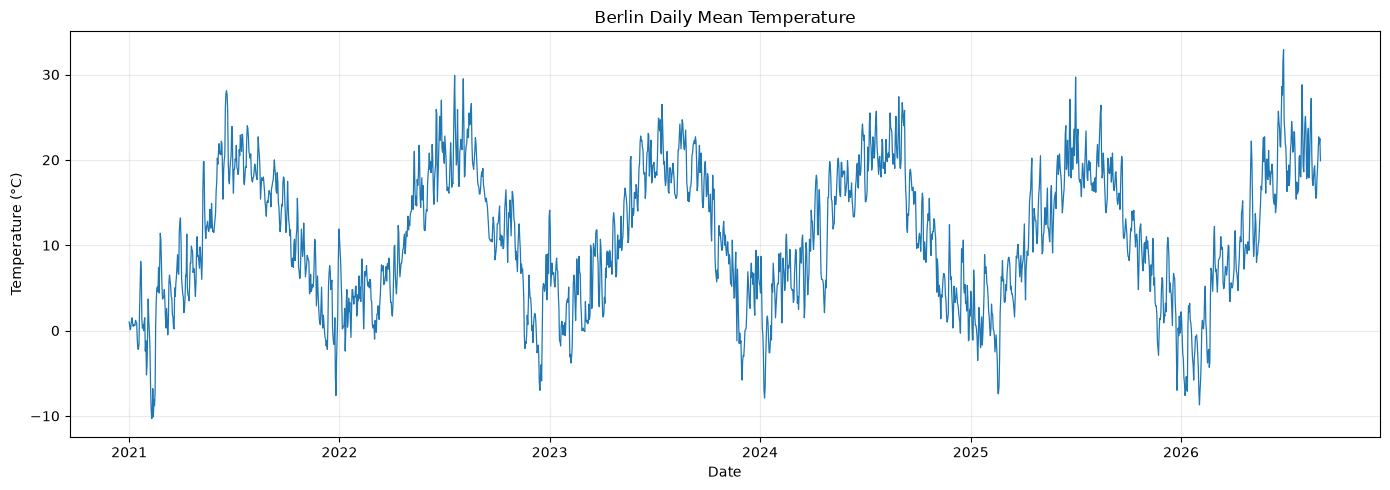

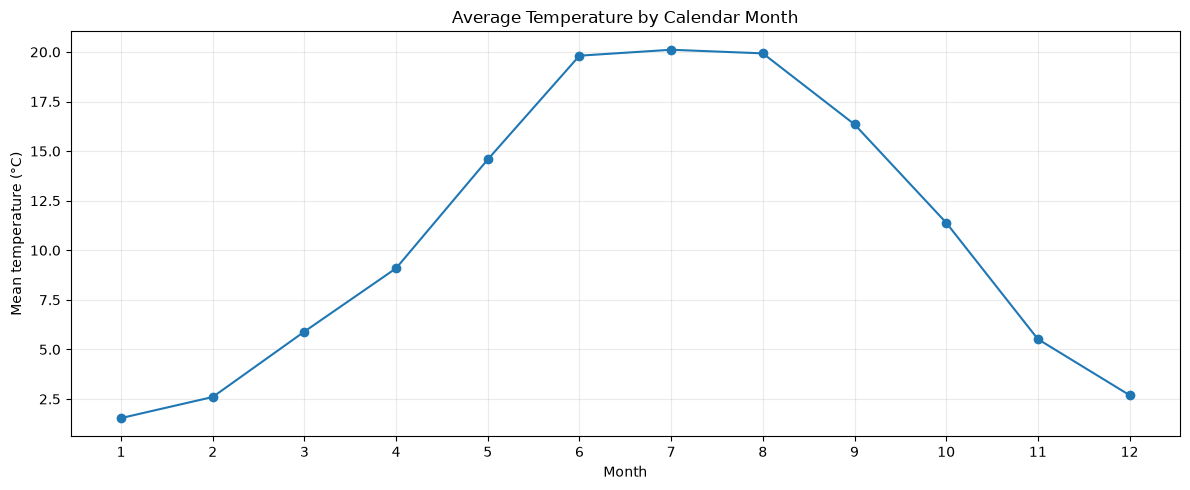

In [6]:
# 7. Exploratory visualisation

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_clean.index, df_clean["temp_mean"], linewidth=0.9)
ax.set_title("Berlin Daily Mean Temperature")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
monthly = df_clean.assign(month=df_clean.index.month).groupby("month")["temp_mean"].mean()
ax.plot(monthly.index, monthly.values, marker="o")
ax.set_xticks(range(1, 13))
ax.set_xlabel("Month")
ax.set_ylabel("Mean temperature (°C)")
ax.set_title("Average Temperature by Calendar Month")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# 8. Chronological train / validation / test split

The split is performed **before model evaluation** and respects temporal order.

- Training: earliest 70%
- Validation: following 15%
- Test: final 15%

The validation period is used for model selection and hyperparameter tuning.

The final rolling-origin test is never used to select hyperparameters.

In [7]:
n = len(df_clean)

train_end_idx = int(n * TRAIN_RATIO) - 1
val_end_idx = int(n * (TRAIN_RATIO + VALIDATION_RATIO)) - 1

train_end_date = df_clean.index[train_end_idx]
val_end_date = df_clean.index[val_end_idx]
test_start_date = df_clean.index[val_end_idx + 1]
test_end_date = df_clean.index[-1]

print("Training end:   ", train_end_date.date())
print("Validation end: ", val_end_date.date())
print("Test start:     ", test_start_date.date())
print("Test end:       ", test_end_date.date())

print("\nApproximate raw observations:")
print("Train:", train_end_idx + 1)
print("Validation:", val_end_idx - train_end_idx)
print("Test:", n - val_end_idx - 1)


Training end:    2024-12-18
Validation end:  2025-10-24
Test start:      2025-10-25
Test end:        2026-08-31

Approximate raw observations:
Train: 1448
Validation: 310
Test: 311


# 9. Calendar features

Calendar variables are deterministic and known at forecast time.

We use annual cyclic encoding rather than separate month dummy variables:

- `day_of_year_sin`
- `day_of_year_cos`

No future weather measurement is used as a model input.

In [8]:
def add_calendar_features(frame):
    out = frame.copy()
    day_of_year = out.index.dayofyear
    out["day_of_year_sin"] = np.sin(2 * np.pi * day_of_year / 365.25)
    out["day_of_year_cos"] = np.cos(2 * np.pi * day_of_year / 365.25)
    return out


# Initial scaler: fitted ONLY on the training period.
train_raw = df_clean.loc[:train_end_date]

feature_scaler = MinMaxScaler()
feature_scaler.fit(train_raw[METEO_FEATURES])

target_scaler = MinMaxScaler()
target_scaler.fit(train_raw[[TARGET]])

scaled_meteo = pd.DataFrame(
    feature_scaler.transform(df_clean[METEO_FEATURES]),
    columns=METEO_FEATURES,
    index=df_clean.index,
)

features_all = add_calendar_features(scaled_meteo)

target_all_scaled = pd.Series(
    target_scaler.transform(df_clean[[TARGET]]).ravel(),
    index=df_clean.index,
    name=TARGET,
)

print("Scaler fitted on:", train_raw.index.min().date(), "to", train_raw.index.max().date())
print("Number of model input features:", features_all.shape[1])


Scaler fitted on: 2021-01-01 to 2024-12-18
Number of model input features: 12


# 10. Direct multi-step sequence construction

Each sample is:

**30 observed days → 7 future daily mean temperatures**

This is the key difference from V1.

The model is not trained for one-step prediction and then recursively fed its own predictions during evaluation.

For each sequence, we record:

- forecast origin
- first target date
- last target date

This lets us enforce clean temporal partitions.

In [9]:
def make_sequences(feature_frame, target_series, lookback=LOOKBACK, horizon=HORIZON):
    X, y = [], []
    origins, target_starts, target_ends = [], [], []

    values = feature_frame.values
    target_values = target_series.values
    dates = feature_frame.index

    for end_idx in range(lookback, len(feature_frame) - horizon + 1):
        X.append(values[end_idx - lookback:end_idx])
        y.append(target_values[end_idx:end_idx + horizon])

        origins.append(dates[end_idx - 1])
        target_starts.append(dates[end_idx])
        target_ends.append(dates[end_idx + horizon - 1])

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.float32),
        pd.DatetimeIndex(origins),
        pd.DatetimeIndex(target_starts),
        pd.DatetimeIndex(target_ends),
    )


X_all, y_all, origins_all, target_starts_all, target_ends_all = make_sequences(
    features_all, target_all_scaled
)

train_mask = target_ends_all <= train_end_date
val_mask = (
    (target_starts_all > train_end_date)
    & (target_ends_all <= val_end_date)
)
test_mask = target_starts_all > val_end_date

X_train = X_all[train_mask]
y_train = y_all[train_mask]

X_val = X_all[val_mask]
y_val = y_all[val_mask]

X_test = X_all[test_mask]
y_test = y_all[test_mask]

test_origins = origins_all[test_mask]

print("All sequences:", X_all.shape, y_all.shape)
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)
print("Test origins:", test_origins.min().date(), "to", test_origins.max().date())


All sequences: (2033, 30, 12) (2033, 7)
Train: (1412, 30, 12) (1412, 7)
Validation: (304, 30, 12) (304, 7)
Test: (305, 30, 12) (305, 7)
Test origins: 2025-10-24 to 2026-08-24


In [10]:
# 11. Utility functions for inverse transformation and metrics

def inverse_targets(y_scaled, scaler):
    arr = np.asarray(y_scaled)
    original_shape = arr.shape
    return scaler.inverse_transform(arr.reshape(-1, 1)).reshape(original_shape)


def smape(y_true, y_pred, eps=1e-8):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean(
        2.0 * np.abs(y_pred - y_true)
        / (np.abs(y_true) + np.abs(y_pred) + eps)
    ) * 100.0


def mase(y_true, y_pred, training_series):
    scale = np.mean(np.abs(np.diff(np.asarray(training_series))))
    if scale == 0:
        return np.nan
    return np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred))) / scale


def horizon_metrics(y_true, y_pred, mase_scale_series=None):
    rows = []
    for h in range(y_true.shape[1]):
        yt = y_true[:, h]
        yp = y_pred[:, h]

        row = {
            "horizon": h + 1,
            "MAE": mean_absolute_error(yt, yp),
            "RMSE": np.sqrt(mean_squared_error(yt, yp)),
            "R2": r2_score(yt, yp),
            "sMAPE": smape(yt, yp),
        }

        if mase_scale_series is not None:
            row["MASE"] = mase(yt, yp, mase_scale_series)

        rows.append(row)

    return pd.DataFrame(rows)


def overall_metrics(y_true, y_pred, mase_scale_series=None):
    yt = np.asarray(y_true).ravel()
    yp = np.asarray(y_pred).ravel()

    result = {
        "MAE": mean_absolute_error(yt, yp),
        "RMSE": np.sqrt(mean_squared_error(yt, yp)),
        "R2": r2_score(yt, yp),
        "sMAPE": smape(yt, yp),
    }

    if mase_scale_series is not None:
        result["MASE"] = mase(yt, yp, mase_scale_series)

    return pd.Series(result)


train_temperature_reference = df_clean.loc[:val_end_date, TARGET].values


# 12. Naive baselines

These are essential because a sophisticated model should demonstrate improvement over simple forecasting rules.

### Persistence

For every horizon:

> forecast = most recently observed temperature

### Weekly seasonal naive

For horizon h:

> forecast(t+h) = observed temperature(t+h−7)

For a 1–7 day forecast, this uses only observations already available at the forecast origin.

**V2.1 evaluation rule:** the baseline results use the same weekly, non-overlapping forecast-origin spacing as the final model comparison.


In [11]:
def persistence_forecast(origin, frame=df_clean, horizon=HORIZON):
    last_value = frame.loc[origin, TARGET]
    return np.repeat(last_value, horizon)


def seasonal_naive_forecast(origin, frame=df_clean, horizon=HORIZON, seasonal_period=7):
    values = []
    for h in range(1, horizon + 1):
        target_date = origin + timedelta(days=h)
        reference_date = target_date - timedelta(days=seasonal_period)
        values.append(frame.loc[reference_date, TARGET])
    return np.asarray(values)


# Baseline evaluation uses the exact same final origins as the neural/Prophet comparison.
baseline_records = []

baseline_candidates = df_clean.index[
    (df_clean.index > val_end_date)
    & (df_clean.index + pd.Timedelta(days=HORIZON) <= test_end_date)
]
baseline_origins = pd.DatetimeIndex(baseline_candidates[::TEST_ORIGIN_STEP_DAYS])

for origin in baseline_origins:
    actual_dates = [origin + timedelta(days=h) for h in range(1, HORIZON + 1)]
    actual = df_clean.loc[actual_dates, TARGET].values

    for model_name, pred in [
        ("Persistence", persistence_forecast(origin)),
        ("SeasonalNaive7", seasonal_naive_forecast(origin)),
    ]:
        for h, (actual_value, pred_value) in enumerate(zip(actual, pred), start=1):
            baseline_records.append({
                "origin": origin,
                "horizon": h,
                "model": model_name,
                "actual": actual_value,
                "prediction": pred_value,
            })

baseline_long = pd.DataFrame(baseline_records)

baseline_summary = (
    baseline_long
    .groupby(["model", "horizon"])
    .apply(lambda g: pd.Series({
        "MAE": mean_absolute_error(g["actual"], g["prediction"]),
        "RMSE": np.sqrt(mean_squared_error(g["actual"], g["prediction"])),
    }))
    .reset_index()
)

display(baseline_summary)


,model,horizon,MAE,RMSE
0,Persistence,1,1.718182,2.245298
1,Persistence,2,2.781818,3.511345
2,Persistence,3,3.090909,3.923125
3,Persistence,4,3.620455,4.470433
4,Persistence,5,4.518182,5.359825
5,Persistence,6,4.752273,5.624722
6,Persistence,7,4.722727,5.847455
7,SeasonalNaive7,1,4.834091,5.960686
8,SeasonalNaive7,2,4.215909,4.959633
9,SeasonalNaive7,3,3.940909,4.673231


# 13. Transformer components

In [12]:
def positional_encoding(length, depth):
    positions = np.arange(length)[:, None]
    dimensions = np.arange(depth)[None, :]

    angle_rates = 1 / np.power(
        10000,
        (2 * (dimensions // 2)) / np.float32(depth)
    )
    angle_rads = positions * angle_rates

    encoding = np.zeros((length, depth), dtype=np.float32)
    encoding[:, 0::2] = np.sin(angle_rads[:, 0::2])
    encoding[:, 1::2] = np.cos(angle_rads[:, 1::2])

    return tf.constant(encoding[None, :, :], dtype=tf.float32)


def transformer_block(x, model_dim, num_heads, ff_dim, dropout_rate):
    key_dim = model_dim // num_heads

    # Pre-norm self-attention
    attn_input = LayerNormalization(epsilon=1e-6)(x)
    attn_output = MultiHeadAttention(
        num_heads=num_heads,
        key_dim=key_dim,
        dropout=dropout_rate,
    )(attn_input, attn_input)

    x = Add()([x, Dropout(dropout_rate)(attn_output)])

    # Pre-norm feed-forward block
    ff_input = LayerNormalization(epsilon=1e-6)(x)
    ff_output = Dense(ff_dim, activation="gelu")(ff_input)
    ff_output = Dropout(dropout_rate)(ff_output)
    ff_output = Dense(model_dim)(ff_output)

    return Add()([x, Dropout(dropout_rate)(ff_output)])


# 14. Model builders

Both neural architectures produce **seven outputs**.

That means the learning problem is explicitly:

**past 30 days → [t+1, t+2, ..., t+7]**

In [13]:
def build_bilstm(
    n_features,
    horizon=HORIZON,
    lstm1_units=64,
    lstm2_units=32,
    dropout_rate=0.2,
    dense_units=32,
    learning_rate=1e-3,
):
    inputs = Input(shape=(LOOKBACK, n_features))

    x = Bidirectional(
        LSTM(lstm1_units, return_sequences=True)
    )(inputs)
    x = Dropout(dropout_rate)(x)

    x = LSTM(lstm2_units, return_sequences=False)(x)
    x = Dropout(dropout_rate)(x)

    x = Dense(dense_units, activation="relu")(x)
    outputs = Dense(horizon)(x)

    model = Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="mse",
        metrics=["mae"],
    )
    return model


def build_transformer(
    n_features,
    horizon=HORIZON,
    model_dim=64,
    num_heads=4,
    ff_dim=128,
    num_blocks=2,
    dropout_rate=0.1,
    dense_units=64,
    learning_rate=1e-3,
):
    assert model_dim % num_heads == 0

    inputs = Input(shape=(LOOKBACK, n_features))

    x = Dense(model_dim)(inputs)
    x = x + positional_encoding(LOOKBACK, model_dim)
    x = Dropout(dropout_rate)(x)

    for _ in range(num_blocks):
        x = transformer_block(
            x,
            model_dim=model_dim,
            num_heads=num_heads,
            ff_dim=ff_dim,
            dropout_rate=dropout_rate,
        )

    x = LayerNormalization(epsilon=1e-6)(x)
    x = GlobalAveragePooling1D()(x)
    x = Dense(dense_units, activation="relu")(x)
    x = Dropout(dropout_rate)(x)
    outputs = Dense(horizon)(x)

    model = Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="mse",
        metrics=["mae"],
    )
    return model


# 15. Default-model validation benchmark

Before tuning, we train a fixed reasonable configuration for each neural model.

This creates a direct **default vs tuned** comparison on the validation period, which is required to answer the research question about whether tuning improves performance.

In [14]:
N_FEATURES = X_train.shape[-1]

DEFAULT_LSTM_CONFIG = {
    "lstm1_units": 64,
    "lstm2_units": 32,
    "dropout_rate": 0.2,
    "dense_units": 32,
    "learning_rate": 1e-3,
}

DEFAULT_TRANSFORMER_CONFIG = {
    "model_dim": 64,
    "num_heads": 4,
    "ff_dim": 128,
    "num_blocks": 2,
    "dropout_rate": 0.1,
    "dense_units": 64,
    "learning_rate": 1e-3,
}

def train_with_early_stopping(model, Xtr, ytr, Xv, yv, epochs=30):
    callbacks = [
        EarlyStopping(
            monitor="val_loss",
            patience=6,
            restore_best_weights=True,
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=1e-6,
        ),
    ]

    history = model.fit(
        Xtr, ytr,
        validation_data=(Xv, yv),
        epochs=epochs,
        batch_size=32,
        shuffle=False,
        callbacks=callbacks,
        verbose=0,
    )
    return history


default_lstm = build_bilstm(N_FEATURES, **DEFAULT_LSTM_CONFIG)
default_lstm_history = train_with_early_stopping(
    default_lstm, X_train, y_train, X_val, y_val
)

default_transformer = build_transformer(
    N_FEATURES, **DEFAULT_TRANSFORMER_CONFIG
)
default_transformer_history = train_with_early_stopping(
    default_transformer, X_train, y_train, X_val, y_val
)

default_lstm_val = inverse_targets(
    default_lstm.predict(X_val, verbose=0), target_scaler
)
default_transformer_val = inverse_targets(
    default_transformer.predict(X_val, verbose=0), target_scaler
)
y_val_actual = inverse_targets(y_val, target_scaler)

default_validation_results = pd.DataFrame({
    "Model": ["Default BiLSTM", "Default Transformer"],
    "MAE": [
        mean_absolute_error(y_val_actual.ravel(), default_lstm_val.ravel()),
        mean_absolute_error(y_val_actual.ravel(), default_transformer_val.ravel()),
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_val_actual.ravel(), default_lstm_val.ravel())),
        np.sqrt(mean_squared_error(y_val_actual.ravel(), default_transformer_val.ravel())),
    ],
    "R2": [
        r2_score(y_val_actual.ravel(), default_lstm_val.ravel()),
        r2_score(y_val_actual.ravel(), default_transformer_val.ravel()),
    ],
})

display(default_validation_results)


E0000 00:00:1790540028.833013 6632793 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1790540053.634806 6632793 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

,Model,MAE,RMSE,R2
0,Default BiLSTM,2.510545,3.182640,0.817979
1,Default Transformer,2.522536,3.214573,0.814308


# 16. Hyperparameter tuning — BiLSTM

The validation set is the only dataset used for hyperparameter selection.

The test set is not touched here.

In [15]:
def bilstm_tuner_builder(hp):
    return build_bilstm(
        N_FEATURES,
        lstm1_units=hp.Choice("lstm1_units", [32, 64, 128]),
        lstm2_units=hp.Choice("lstm2_units", [16, 32, 64]),
        dropout_rate=hp.Choice("dropout_rate", [0.1, 0.2, 0.3]),
        dense_units=hp.Choice("dense_units", [16, 32, 64]),
        learning_rate=hp.Choice("learning_rate", [1e-3, 5e-4, 1e-4]),
    )


if RUN_TUNING:
    lstm_tuner = kt.RandomSearch(
        bilstm_tuner_builder,
        objective="val_loss",
        max_trials=LSTM_MAX_TRIALS,
        overwrite=True,
        directory="v2_tuner",
        project_name="bilstm_7day",
    )

    lstm_tuner.search(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=TUNER_MAX_EPOCHS,
        batch_size=32,
        shuffle=False,
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=5,
                restore_best_weights=True,
            )
        ],
        verbose=0,
    )

    best_lstm_hp = lstm_tuner.get_best_hyperparameters(1)[0]
    best_lstm_config = {
        "lstm1_units": best_lstm_hp.get("lstm1_units"),
        "lstm2_units": best_lstm_hp.get("lstm2_units"),
        "dropout_rate": best_lstm_hp.get("dropout_rate"),
        "dense_units": best_lstm_hp.get("dense_units"),
        "learning_rate": best_lstm_hp.get("learning_rate"),
    }

    best_lstm_trial = lstm_tuner.oracle.get_best_trials(1)[0]
    try:
        best_lstm_epochs = int(
            best_lstm_trial.metrics.get_best_step("val_loss")
        ) + 1
    except Exception:
        best_lstm_epochs = TUNER_MAX_EPOCHS
else:
    best_lstm_config = DEFAULT_LSTM_CONFIG.copy()
    best_lstm_epochs = 20

print("Best BiLSTM configuration:")
print(best_lstm_config)
print("Selected training epochs:", best_lstm_epochs)


E0000 00:00:1790540090.472036 6632793 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1790540103.003721 6632793 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

Best BiLSTM configuration:
{'lstm1_units': 128, 'lstm2_units': 64, 'dropout_rate': 0.3, 'dense_units': 16, 'learning_rate': 0.0005}
Selected training epochs: 12


# 17. Hyperparameter tuning — Transformer

In [16]:
def transformer_tuner_builder(hp):
    model_dim = hp.Choice("model_dim", [32, 64, 96])
    num_heads = hp.Choice("num_heads", [2, 4, 8])

    return build_transformer(
        N_FEATURES,
        model_dim=model_dim,
        num_heads=num_heads,
        ff_dim=hp.Choice("ff_dim", [64, 128, 192]),
        num_blocks=hp.Choice("num_blocks", [1, 2, 3]),
        dropout_rate=hp.Choice("dropout_rate", [0.05, 0.1, 0.2]),
        dense_units=hp.Choice("dense_units", [32, 64, 96]),
        learning_rate=hp.Choice("learning_rate", [1e-3, 5e-4, 1e-4]),
    )


if RUN_TUNING:
    transformer_tuner = kt.RandomSearch(
        transformer_tuner_builder,
        objective="val_loss",
        max_trials=TRANSFORMER_MAX_TRIALS,
        overwrite=True,
        directory="v2_tuner",
        project_name="transformer_7day",
    )

    transformer_tuner.search(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=TUNER_MAX_EPOCHS,
        batch_size=32,
        shuffle=False,
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=5,
                restore_best_weights=True,
            )
        ],
        verbose=0,
    )

    best_transformer_hp = transformer_tuner.get_best_hyperparameters(1)[0]
    best_transformer_config = {
        "model_dim": best_transformer_hp.get("model_dim"),
        "num_heads": best_transformer_hp.get("num_heads"),
        "ff_dim": best_transformer_hp.get("ff_dim"),
        "num_blocks": best_transformer_hp.get("num_blocks"),
        "dropout_rate": best_transformer_hp.get("dropout_rate"),
        "dense_units": best_transformer_hp.get("dense_units"),
        "learning_rate": best_transformer_hp.get("learning_rate"),
    }

    best_transformer_trial = transformer_tuner.oracle.get_best_trials(1)[0]
    try:
        best_transformer_epochs = int(
            best_transformer_trial.metrics.get_best_step("val_loss")
        ) + 1
    except Exception:
        best_transformer_epochs = TUNER_MAX_EPOCHS
else:
    best_transformer_config = DEFAULT_TRANSFORMER_CONFIG.copy()
    best_transformer_epochs = 20

print("Best Transformer configuration:")
print(best_transformer_config)
print("Selected training epochs:", best_transformer_epochs)


E0000 00:00:1790540203.760778 6632793 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1790540219.644331 6632793 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

Best Transformer configuration:
{'model_dim': 64, 'num_heads': 2, 'ff_dim': 192, 'num_blocks': 2, 'dropout_rate': 0.1, 'dense_units': 96, 'learning_rate': 0.0005}
Selected training epochs: 9


# 18. Tuned vs default validation comparison

This comparison is performed before the final test evaluation.

It directly addresses:

> **Does hyperparameter tuning improve predictive performance?**

In [17]:
tuned_lstm = build_bilstm(N_FEATURES, **best_lstm_config)
tuned_lstm_history = train_with_early_stopping(
    tuned_lstm, X_train, y_train, X_val, y_val,
    epochs=max(best_lstm_epochs, 10)
)

tuned_transformer = build_transformer(
    N_FEATURES, **best_transformer_config
)
tuned_transformer_history = train_with_early_stopping(
    tuned_transformer, X_train, y_train, X_val, y_val,
    epochs=max(best_transformer_epochs, 10)
)

tuned_lstm_val = inverse_targets(
    tuned_lstm.predict(X_val, verbose=0), target_scaler
)
tuned_transformer_val = inverse_targets(
    tuned_transformer.predict(X_val, verbose=0), target_scaler
)

tuning_comparison = pd.DataFrame([
    {
        "Model": "Default BiLSTM",
        **overall_metrics(y_val_actual, default_lstm_val),
    },
    {
        "Model": "Tuned BiLSTM",
        **overall_metrics(y_val_actual, tuned_lstm_val),
    },
    {
        "Model": "Default Transformer",
        **overall_metrics(y_val_actual, default_transformer_val),
    },
    {
        "Model": "Tuned Transformer",
        **overall_metrics(y_val_actual, tuned_transformer_val),
    },
])

display(tuning_comparison.round(4))


E0000 00:00:1790540359.179248 6632793 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1790540379.881582 6632793 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

,Model,MAE,RMSE,R2,sMAPE
0,Default BiLSTM,2.5105,3.1826,0.8180,40.0892
1,Tuned BiLSTM,2.4971,3.1412,0.8227,40.9368
2,Default Transformer,2.5225,3.2146,0.8143,41.4960
3,Tuned Transformer,2.5965,3.3185,0.8021,42.4345


# 19. Prophet hyperparameter tuning

Prophet is tuned on validation forecast origins only.

Crucially, **future meteorological regressors are not supplied**.

The Prophet comparison therefore uses the same information class as the historical-only neural forecasting task:

- past target temperature
- known calendar dates
- learned trend/seasonality

No future humidity, radiation, precipitation or wind values are used.

In [18]:
PROPHET_PARAM_SPACE = {
    "changepoint_prior_scale": [0.01, 0.05, 0.1, 0.5],
    "seasonality_prior_scale": [0.1, 1.0, 5.0, 10.0],
    "seasonality_mode": ["additive", "multiplicative"],
    "changepoint_range": [0.8, 0.9],
}

def fit_prophet(train_frame, params):
    model = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=False,
        daily_seasonality=False,
        **params,
    )
    prophet_train = (
        train_frame[[TARGET]]
        .reset_index()
        .rename(columns={"date": "ds", TARGET: "y"})
    )
    model.fit(prophet_train)
    return model


# Choose three validation origins with a full 7-day future available.
validation_candidates = df_clean.index[
    (df_clean.index > train_end_date)
    & (df_clean.index + pd.Timedelta(days=HORIZON) <= val_end_date)
]

if len(validation_candidates) > 0:
    idxs = np.linspace(
        0, len(validation_candidates) - 1,
        min(3, len(validation_candidates)),
        dtype=int
    )
    prophet_val_origins = pd.DatetimeIndex(
        validation_candidates[np.unique(idxs)]
    )
else:
    prophet_val_origins = pd.DatetimeIndex([])

print("Prophet validation origins:")
for d in prophet_val_origins:
    print(" ", d.date())


Prophet validation origins:
  2024-12-19
  2025-05-19
  2025-10-17


In [19]:
import itertools

def sample_prophet_configs(param_space, n=12, seed=SEED):
    all_configs = [
        dict(zip(param_space.keys(), values))
        for values in itertools.product(*param_space.values())
    ]

    rng = np.random.default_rng(seed)
    if n >= len(all_configs):
        return all_configs

    chosen = rng.choice(len(all_configs), size=n, replace=False)
    return [all_configs[i] for i in chosen]


prophet_configs = sample_prophet_configs(PROPHET_PARAM_SPACE, n=12)

prophet_tuning_rows = []

for config_id, params in enumerate(prophet_configs, start=1):
    fold_errors = []

    for origin in prophet_val_origins:
        train_frame = df_clean.loc[:origin]
        actual_dates = [origin + timedelta(days=h) for h in range(1, HORIZON + 1)]
        actual = df_clean.loc[actual_dates, TARGET].values

        model = fit_prophet(train_frame, params)

        future = pd.DataFrame({"ds": pd.to_datetime(actual_dates)})
        pred = model.predict(future)["yhat"].values

        fold_errors.append(mean_absolute_error(actual, pred))

    prophet_tuning_rows.append({
        "config_id": config_id,
        **params,
        "validation_MAE": np.mean(fold_errors),
    })

prophet_tuning_results = pd.DataFrame(prophet_tuning_rows).sort_values(
    "validation_MAE"
)

best_prophet_row = prophet_tuning_results.iloc[0]
best_prophet_config = {
    key: best_prophet_row[key]
    for key in PROPHET_PARAM_SPACE.keys()
}

display(prophet_tuning_results.head(10))
print("\nSelected Prophet configuration:")
print(best_prophet_config)


22:19:53 - cmdstanpy - INFO - Chain [1] start processing
22:19:53 - cmdstanpy - INFO - Chain [1] done processing
22:19:53 - cmdstanpy - INFO - Chain [1] start processing
22:19:53 - cmdstanpy - INFO - Chain [1] done processing
22:19:53 - cmdstanpy - INFO - Chain [1] start processing
22:19:53 - cmdstanpy - INFO - Chain [1] done processing
22:19:53 - cmdstanpy - INFO - Chain [1] start processing
22:19:53 - cmdstanpy - INFO - Chain [1] done processing
22:19:53 - cmdstanpy - INFO - Chain [1] start processing
22:19:53 - cmdstanpy - INFO - Chain [1] done processing
22:19:53 - cmdstanpy - INFO - Chain [1] start processing
22:19:53 - cmdstanpy - INFO - Chain [1] done processing
22:19:53 - cmdstanpy - INFO - Chain [1] start processing
22:19:54 - cmdstanpy - INFO - Chain [1] done processing
22:19:54 - cmdstanpy - INFO - Chain [1] start processing
22:19:54 - cmdstanpy - INFO - Chain [1] done processing
22:19:54 - cmdstanpy - INFO - Chain [1] start processing
22:19:54 - cmdstanpy - INFO - Chain [1]

,config_id,changepoint_prior_scale,seasonality_prior_scale,seasonality_mode,changepoint_range,validation_MAE
4,5,0.10,1.0,additive,0.8,2.125609
3,4,0.10,0.1,additive,0.9,2.126431
7,8,0.50,5.0,additive,0.8,2.136152
2,3,0.10,5.0,additive,0.9,2.137014
0,1,0.05,5.0,additive,0.8,2.144401
10,11,0.50,10.0,multiplicative,0.8,2.158276
9,10,0.50,5.0,multiplicative,0.9,2.177017
5,6,0.50,0.1,additive,0.9,2.187870
8,9,0.50,10.0,additive,0.9,2.199085
1,2,0.01,1.0,additive,0.9,2.262304



Selected Prophet configuration:
{'changepoint_prior_scale': np.float64(0.1), 'seasonality_prior_scale': np.float64(1.0), 'seasonality_mode': 'additive', 'changepoint_range': np.float64(0.8)}


# 20. Rolling-origin test design

The final evaluation uses **weekly, non-overlapping forecast origins** from the untouched test period.

For every origin, the models forecast the same next seven calendar days. Origins are spaced seven days apart, so the seven-day target windows do not overlap.

This produces a collection of genuine 1–7 day forecasts while reducing dependence between adjacent forecast errors.


In [20]:
# 20. Weekly non-overlapping rolling-origin test design
#
# Use every 7th eligible test origin. Each forecast therefore covers a distinct
# seven-day target window, which reduces dependence caused by overlapping horizons.

test_origin_candidates = df_clean.index[
    (df_clean.index > val_end_date)
    & (df_clean.index + pd.Timedelta(days=HORIZON) <= test_end_date)
]

selected_test_origins = pd.DatetimeIndex(
    test_origin_candidates[::TEST_ORIGIN_STEP_DAYS]
)

print("Eligible test origins:", len(test_origin_candidates))
print("Selected weekly non-overlapping origins:", len(selected_test_origins))
print("First origin:", selected_test_origins.min().date())
print("Last origin: ", selected_test_origins.max().date())

# Verify the spacing and forecast-window validity.
if len(selected_test_origins) > 1:
    gaps = np.diff(selected_test_origins.values).astype("timedelta64[D]").astype(int)
    assert np.all(gaps == TEST_ORIGIN_STEP_DAYS), gaps
assert all(
    origin + pd.Timedelta(days=HORIZON) <= test_end_date
    for origin in selected_test_origins
)

print("\nSelected final test forecast origins:")
for d in selected_test_origins:
    print(" ", d.date())


Eligible test origins: 304
Selected weekly non-overlapping origins: 44
First origin: 2025-10-25
Last origin:  2026-08-22

Selected final test forecast origins:
  2025-10-25
  2025-11-01
  2025-11-08
  2025-11-15
  2025-11-22
  2025-11-29
  2025-12-06
  2025-12-13
  2025-12-20
  2025-12-27
  2026-01-03
  2026-01-10
  2026-01-17
  2026-01-24
  2026-01-31
  2026-02-07
  2026-02-14
  2026-02-21
  2026-02-28
  2026-03-07
  2026-03-14
  2026-03-21
  2026-03-28
  2026-04-04
  2026-04-11
  2026-04-18
  2026-04-25
  2026-05-02
  2026-05-09
  2026-05-16
  2026-05-23
  2026-05-30
  2026-06-06
  2026-06-13
  2026-06-20
  2026-06-27
  2026-07-04
  2026-07-11
  2026-07-18
  2026-07-25
  2026-08-01
  2026-08-08
  2026-08-15
  2026-08-22


# 21. Rolling-origin model utilities

For each final test origin, the neural networks are retrained using only data available at that origin.

The previously selected hyperparameters are kept fixed.

This avoids using the test period to tune architecture choices while still allowing the model to learn from newly available historical observations.

In [21]:
def build_scaled_history_until(origin):
    available = df_clean.loc[:origin].copy()

    scaler_x = MinMaxScaler()
    scaler_x.fit(available[METEO_FEATURES])

    scaler_y = MinMaxScaler()
    scaler_y.fit(available[[TARGET]])

    scaled = pd.DataFrame(
        scaler_x.transform(available[METEO_FEATURES]),
        columns=METEO_FEATURES,
        index=available.index,
    )

    featured = add_calendar_features(scaled)

    target_scaled = pd.Series(
        scaler_y.transform(available[[TARGET]]).ravel(),
        index=available.index,
        name=TARGET,
    )

    return available, scaler_x, scaler_y, featured, target_scaled


def train_predict_bilstm_at_origin(origin):
    available, scaler_x, scaler_y, featured, target_scaled = (
        build_scaled_history_until(origin)
    )

    X_seq, y_seq, _, _, _ = make_sequences(
        featured, target_scaled, LOOKBACK, HORIZON
    )

    model = build_bilstm(
        X_seq.shape[-1],
        **best_lstm_config
    )

    model.fit(
        X_seq, y_seq,
        epochs=max(best_lstm_epochs, 10),
        batch_size=32,
        shuffle=False,
        verbose=0,
    )

    last_sequence = featured.iloc[-LOOKBACK:].values.astype(np.float32)
    pred_scaled = model.predict(
        last_sequence[None, :, :], verbose=0
    )[0]

    prediction = scaler_y.inverse_transform(
        pred_scaled.reshape(-1, 1)
    ).ravel()

    return prediction


def train_predict_transformer_at_origin(origin):
    available, scaler_x, scaler_y, featured, target_scaled = (
        build_scaled_history_until(origin)
    )

    X_seq, y_seq, _, _, _ = make_sequences(
        featured, target_scaled, LOOKBACK, HORIZON
    )

    model = build_transformer(
        X_seq.shape[-1],
        **best_transformer_config
    )

    model.fit(
        X_seq, y_seq,
        epochs=max(best_transformer_epochs, 10),
        batch_size=32,
        shuffle=False,
        verbose=0,
    )

    last_sequence = featured.iloc[-LOOKBACK:].values.astype(np.float32)
    pred_scaled = model.predict(
        last_sequence[None, :, :], verbose=0
    )[0]

    prediction = scaler_y.inverse_transform(
        pred_scaled.reshape(-1, 1)
    ).ravel()

    return prediction


def prophet_predict_at_origin(origin):
    available = df_clean.loc[:origin]

    model = fit_prophet(
        available,
        best_prophet_config
    )

    future_dates = [
        origin + timedelta(days=h)
        for h in range(1, HORIZON + 1)
    ]

    future = pd.DataFrame({"ds": pd.to_datetime(future_dates)})
    return model.predict(future)["yhat"].values


# 22. Run the final rolling-origin evaluation

This is the most computationally expensive section.

The test period is untouched until this point.

In [22]:
rolling_records = []

if RUN_ROLLING_EVALUATION:
    for origin_number, origin in enumerate(selected_test_origins, start=1):
        print(
            f"[{origin_number}/{len(selected_test_origins)}] "
            f"Forecast origin: {origin.date()}"
        )

        actual_dates = [
            origin + timedelta(days=h)
            for h in range(1, HORIZON + 1)
        ]
        actual = df_clean.loc[actual_dates, TARGET].values

        predictions = {
            "Persistence": persistence_forecast(origin),
            "SeasonalNaive7": seasonal_naive_forecast(origin),
            "Prophet": prophet_predict_at_origin(origin),
            "BiLSTM": train_predict_bilstm_at_origin(origin),
            "Transformer": train_predict_transformer_at_origin(origin),
        }

        for model_name, pred in predictions.items():
            for h, (actual_value, pred_value) in enumerate(
                zip(actual, pred), start=1
            ):
                rolling_records.append({
                    "origin": origin,
                    "target_date": actual_dates[h - 1],
                    "horizon": h,
                    "model": model_name,
                    "actual": actual_value,
                    "prediction": pred_value,
                    "error": pred_value - actual_value,
                    "absolute_error": abs(pred_value - actual_value),
                })

    rolling_results = pd.DataFrame(rolling_records)
    rolling_results.to_csv("v2_rolling_predictions.csv", index=False)

    print("\nSaved: v2_rolling_predictions.csv")
else:
    rolling_results = pd.DataFrame()
    print("Rolling evaluation disabled.")


22:19:59 - cmdstanpy - INFO - Chain [1] start processing
22:19:59 - cmdstanpy - INFO - Chain [1] done processing


[1/44] Forecast origin: 2025-10-25


E0000 00:00:1790540399.696354 6632793 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1790540425.734494 6632793 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

[2/44] Forecast origin: 2025-11-01


22:20:39 - cmdstanpy - INFO - Chain [1] done processing
E0000 00:00:1790540464.777184 6632793 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1790540477.512388 6632793 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
22:21:17 - cmdstanpy - INFO - Chain [1] start processing


... (81 outputs left out)

22:50:33 - cmdstanpy - INFO - Chain [1] done processing
E0000 00:00:1790542260.952032 6632793 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
E0000 00:00:1790542276.108626 6632793 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Ta

[44/44] Forecast origin: 2026-08-22


22:51:16 - cmdstanpy - INFO - Chain [1] done processing
E0000 00:00:1790542304.129805 6632793 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
E0000 00:00:1790542319.199625 6632793 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Ta


Saved: v2_rolling_predictions.csv


# 23. Final horizon-by-horizon comparison

The key thesis table should be based on this output.

The table answers:

> How does forecasting error change from day 1 through day 7?

Do not collapse the entire problem into one overall score.

In [23]:
if not rolling_results.empty:
    horizon_table = (
        rolling_results
        .groupby(["model", "horizon"])
        .apply(lambda g: pd.Series({
            "MAE": mean_absolute_error(g["actual"], g["prediction"]),
            "RMSE": np.sqrt(mean_squared_error(g["actual"], g["prediction"])),
            "R2": r2_score(g["actual"], g["prediction"]),
            "sMAPE": smape(g["actual"], g["prediction"]),
            "MASE": mase(g["actual"], g["prediction"], train_temperature_reference),
        }))
        .reset_index()
    )

    display(
        horizon_table
        .pivot(index="horizon", columns="model", values="MAE")
        .round(3)
    )

    display(
        horizon_table
        .pivot(index="horizon", columns="model", values="RMSE")
        .round(3)
    )


model,BiLSTM,Persistence,Prophet,SeasonalNaive7,Transformer
horizon,,,,,
1,2.894,1.718,3.419,4.834,3.843
2,2.698,2.782,2.945,4.216,3.175
3,2.818,3.091,2.688,3.941,3.093
4,2.991,3.620,2.842,3.989,3.076
5,3.403,4.518,3.359,4.884,3.469
6,3.537,4.752,3.624,5.120,3.615
7,3.330,4.723,3.490,4.723,3.704


model,BiLSTM,Persistence,Prophet,SeasonalNaive7,Transformer
horizon,,,,,
1,3.665,2.245,4.356,5.961,4.935
2,3.390,3.511,3.774,4.960,3.969
3,3.364,3.923,3.546,4.673,3.934
4,3.508,4.470,3.544,4.756,3.756
5,4.221,5.360,4.244,6.002,4.221
6,4.219,5.625,4.308,6.180,4.176
7,4.310,5.847,4.444,5.847,4.434


# 24. Overall test metrics

Use this table as a compact summary, but keep the horizon-specific table as the primary result.

In [24]:
if not rolling_results.empty:
    overall_rows = []

    for model_name, group in rolling_results.groupby("model"):
        overall_rows.append({
            "Model": model_name,
            "MAE": mean_absolute_error(
                group["actual"], group["prediction"]
            ),
            "RMSE": np.sqrt(
                mean_squared_error(group["actual"], group["prediction"])
            ),
            "R2": r2_score(group["actual"], group["prediction"]),
            "sMAPE": smape(
                group["actual"], group["prediction"]
            ),
"MASE": mase(
                group["actual"], group["prediction"], train_temperature_reference
            ),
        })

    overall_test_table = (
        pd.DataFrame(overall_rows)
        .sort_values("MAE")
        .reset_index(drop=True)
    )

    display(overall_test_table.round(4))


,Model,MAE,RMSE,R2,sMAPE,MASE
0,BiLSTM,3.0958,3.8312,0.8149,62.1939,1.8726
1,Prophet,3.1953,4.0476,0.7934,62.8409,1.9328
2,Transformer,3.4250,4.2192,0.7755,64.8409,2.0718
3,Persistence,3.6006,4.5873,0.7346,58.9364,2.1780
4,SeasonalNaive7,4.5295,5.5160,0.6163,70.4295,2.7399


# 24A. Uncertainty across forecast origins

A single overall MAE is not sufficient to show how stable a model is across different forecast origins. Because the seven horizons within an origin are related, uncertainty is estimated by bootstrapping **forecast origins**, not individual daily predictions.

The table reports the mean overall MAE across origins and a 95% bootstrap confidence interval. These intervals describe variability across the selected Berlin test origins; they are not a guarantee of performance on other locations or future periods.


In [25]:
if not rolling_results.empty:
    rng = np.random.default_rng(SEED)
    N_BOOTSTRAP = 2000

    origin_mae_rows = []
    for (origin, model_name), g in rolling_results.groupby(["origin", "model"]):
        origin_mae_rows.append({
            "origin": origin,
            "model": model_name,
            "MAE": mean_absolute_error(g["actual"], g["prediction"]),
            "RMSE": np.sqrt(mean_squared_error(g["actual"], g["prediction"])),
        })

    origin_metrics = pd.DataFrame(origin_mae_rows)
    ci_rows = []

    for model_name, g in origin_metrics.groupby("model"):
        values = g["MAE"].to_numpy()
        bootstrap_means = np.array([
            rng.choice(values, size=len(values), replace=True).mean()
            for _ in range(N_BOOTSTRAP)
        ])
        ci_rows.append({
            "Model": model_name,
            "Mean_origin_MAE": values.mean(),
            "MAE_CI_2.5%": np.percentile(bootstrap_means, 2.5),
            "MAE_CI_97.5%": np.percentile(bootstrap_means, 97.5),
            "N_origins": len(values),
        })

    origin_bootstrap_ci = pd.DataFrame(ci_rows).sort_values("Mean_origin_MAE")
    display(origin_bootstrap_ci.round(4))

    # Paired difference versus persistence, calculated at the origin level.
    persistence_origin = origin_metrics[origin_metrics["model"] == "Persistence"][["origin", "MAE"]].rename(
        columns={"MAE": "Persistence_MAE"}
    )
    paired = origin_metrics.merge(persistence_origin, on="origin", how="inner")
    paired = paired[paired["model"] != "Persistence"].copy()
    paired["MAE_difference_vs_persistence"] = paired["MAE"] - paired["Persistence_MAE"]

    display(
        paired.groupby("model")["MAE_difference_vs_persistence"]
        .agg(["mean", "median", "min", "max"])
        .round(4)
    )
else:
    origin_metrics = pd.DataFrame()
    origin_bootstrap_ci = pd.DataFrame()


,Model,Mean_origin_MAE,MAE_CI_2.5%,MAE_CI_97.5%,N_origins
0,BiLSTM,3.0958,2.6846,3.5180,44
2,Prophet,3.1953,2.7459,3.6670,44
4,Transformer,3.4250,2.9968,3.8688,44
1,Persistence,3.6006,3.0431,4.1731,44
3,SeasonalNaive7,4.5295,4.0555,5.0614,44


,mean,median,min,max
model,,,,
BiLSTM,-0.5049,-0.1093,-6.9776,3.6344
Prophet,-0.4054,-0.3007,-6.9477,4.4305
SeasonalNaive7,0.9289,0.8857,-4.5714,6.0286
Transformer,-0.1756,0.1603,-6.6038,4.7954


# 25. Forecast-error growth with horizon

A strong thesis figure is the relationship between forecast horizon and error.

A useful interpretation is not simply "Model X wins", but:

- Does error increase with horizon?
- Which models degrade fastest?
- Do simple baselines remain competitive?
- Does the Transformer improve or deteriorate relative to recurrent forecasting as the horizon increases?

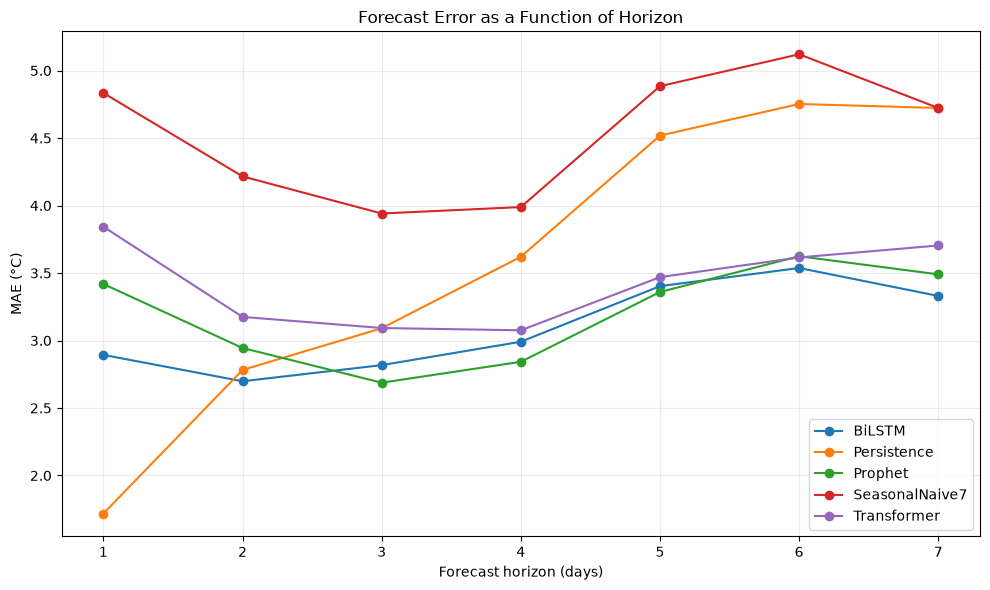

In [26]:
if not rolling_results.empty:
    fig, ax = plt.subplots(figsize=(10, 6))

    for model_name, group in rolling_results.groupby("model"):
        by_h = group.groupby("horizon")["absolute_error"].mean()
        ax.plot(by_h.index, by_h.values, marker="o", label=model_name)

    ax.set_xlabel("Forecast horizon (days)")
    ax.set_ylabel("MAE (°C)")
    ax.set_title("Forecast Error as a Function of Horizon")
    ax.set_xticks(range(1, HORIZON + 1))
    ax.grid(alpha=0.25)
    ax.legend()
    plt.tight_layout()
    plt.show()


# 26. Prediction example from a final test origin

This visual is useful for the thesis because it shows a complete seven-day forecast rather than a sequence of one-step predictions.

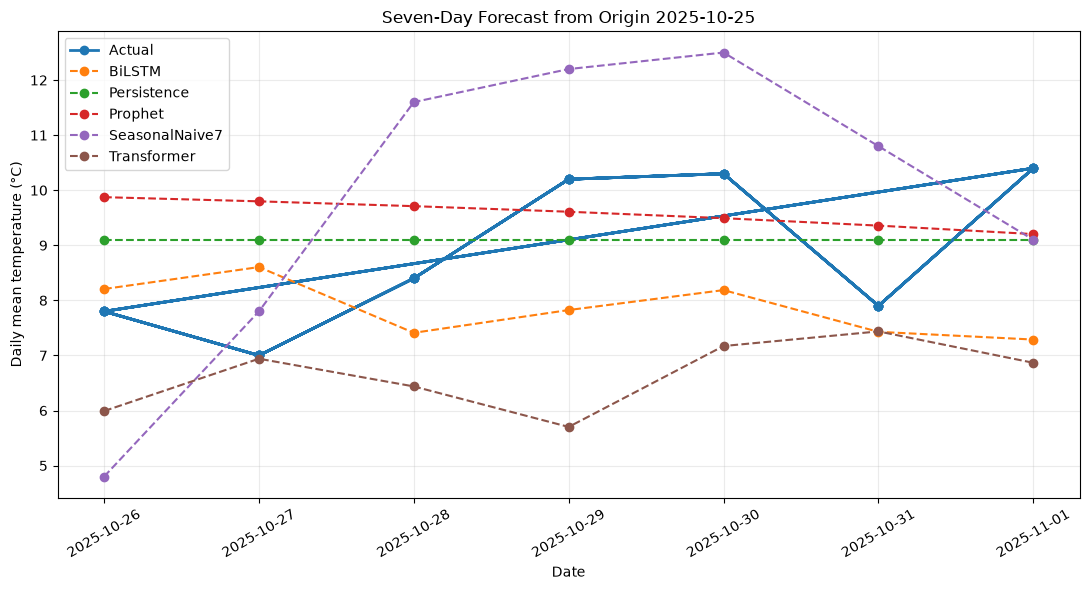

In [27]:
if not rolling_results.empty:
    example_origin = selected_test_origins[0]
    example = rolling_results[
        rolling_results["origin"] == example_origin
    ].copy()

    fig, ax = plt.subplots(figsize=(11, 6))

    actual_dates = pd.to_datetime(example["target_date"])
    ax.plot(
        actual_dates,
        example["actual"],
        marker="o",
        linewidth=2,
        label="Actual",
    )

    for model_name, group in example.groupby("model"):
        ax.plot(
            pd.to_datetime(group["target_date"]),
            group["prediction"],
            marker="o",
            linestyle="--",
            label=model_name,
        )

    ax.set_title(
        f"Seven-Day Forecast from Origin {example_origin.date()}"
    )
    ax.set_xlabel("Date")
    ax.set_ylabel("Daily mean temperature (°C)")
    ax.grid(alpha=0.25)
    ax.legend()
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()


# 27. Optional feature ablation — BiLSTM

This experiment can support a stronger thesis contribution:

> Does adding meteorological variables actually improve forecasting beyond historical temperature and calendar information?

The default is `RUN_FEATURE_ABLATION = False` because it adds training time.

If enabled, compare:

1. Temperature history + calendar features
2. All historical meteorological variables + calendar features

In [28]:
if RUN_FEATURE_ABLATION:
    print("Feature ablation is enabled.")
    print("Recommended interpretation: compare validation MAE/RMSE, not just training loss.")

    # Temperature-only feature set
    temp_feature_cols = ["temp_mean"]
    temp_scaler = MinMaxScaler()
    temp_scaler.fit(train_raw[temp_feature_cols])

    temp_scaled = pd.DataFrame(
        temp_scaler.transform(df_clean[temp_feature_cols]),
        columns=temp_feature_cols,
        index=df_clean.index,
    )
    temp_features = add_calendar_features(temp_scaled)

    temp_target_scaler = MinMaxScaler()
    temp_target_scaler.fit(train_raw[[TARGET]])
    temp_target_scaled = pd.Series(
        temp_target_scaler.transform(df_clean[[TARGET]]).ravel(),
        index=df_clean.index,
    )

    Xa, ya, _, tsa, tea = make_sequences(
        temp_features, temp_target_scaled
    )

    tr = tea <= train_end_date
    va = (tsa > train_end_date) & (tea <= val_end_date)

    ablation_model = build_bilstm(
        Xa.shape[-1],
        **best_lstm_config
    )
    ablation_model.fit(
        Xa[tr], ya[tr],
        validation_data=(Xa[va], ya[va]),
        epochs=max(best_lstm_epochs, 10),
        batch_size=32,
        shuffle=False,
        verbose=0,
    )

    ablation_pred = inverse_targets(
        ablation_model.predict(Xa[va], verbose=0),
        temp_target_scaler
    )
    ablation_true = inverse_targets(
        ya[va],
        temp_target_scaler
    )

    print("Temperature-history-only validation results:")
    print(
        overall_metrics(
            ablation_true,
            ablation_pred
        ).round(4)
    )
else:
    print("Feature ablation disabled.")


Feature ablation disabled.


# 28. Optional lookback-window sensitivity

The original thesis selected 30 days without a systematic sensitivity analysis.

If enabled, test several lookback values using the same validation protocol.

Suggested values:

- 7 days
- 14 days
- 30 days
- 60 days
- 90 days

This can become a useful methodological discussion point.

In [29]:
if RUN_LOOKBACK_ABLATION:
    LOOKBACK_VALUES = [7, 14, 30, 60, 90]
    print(
        "Lookback ablation requested. "
        "Run this as a separate experiment and record validation MAE/RMSE."
    )
    print("Lookback values:", LOOKBACK_VALUES)
else:
    print("Lookback ablation disabled.")


Lookback ablation disabled.


# 29. Optional live 7-day forecast

Unlike V1, the direct multi-output neural models do not need future humidity, radiation, precipitation, or wind values to produce the seven-day forecast.

The model consumes the latest 30 observed days and directly outputs seven temperatures.

For the thesis, record the exact data retrieval date/time alongside any live forecast.

In [30]:
def train_full_model_for_live_forecast():
    available = df_clean.copy()

    scaler_x = MinMaxScaler()
    scaler_x.fit(available[METEO_FEATURES])

    scaler_y = MinMaxScaler()
    scaler_y.fit(available[[TARGET]])

    scaled = pd.DataFrame(
        scaler_x.transform(available[METEO_FEATURES]),
        columns=METEO_FEATURES,
        index=available.index,
    )
    featured = add_calendar_features(scaled)

    target_scaled = pd.Series(
        scaler_y.transform(available[[TARGET]]).ravel(),
        index=available.index,
    )

    X_live, y_live, _, _, _ = make_sequences(
        featured, target_scaled
    )

    bilstm = build_bilstm(
        X_live.shape[-1],
        **best_lstm_config
    )
    bilstm.fit(
        X_live, y_live,
        epochs=max(best_lstm_epochs, 10),
        batch_size=32,
        shuffle=False,
        verbose=0,
    )

    transformer = build_transformer(
        X_live.shape[-1],
        **best_transformer_config
    )
    transformer.fit(
        X_live, y_live,
        epochs=max(best_transformer_epochs, 10),
        batch_size=32,
        shuffle=False,
        verbose=0,
    )

    prophet = fit_prophet(
        available,
        best_prophet_config
    )

    last_sequence = featured.iloc[-LOOKBACK:].values.astype(np.float32)

    lstm_scaled = bilstm.predict(
        last_sequence[None, :, :], verbose=0
    )[0]
    transformer_scaled = transformer.predict(
        last_sequence[None, :, :], verbose=0
    )[0]

    lstm_forecast = scaler_y.inverse_transform(
        lstm_scaled.reshape(-1, 1)
    ).ravel()

    transformer_forecast = scaler_y.inverse_transform(
        transformer_scaled.reshape(-1, 1)
    ).ravel()

    forecast_dates = [
        available.index[-1] + timedelta(days=h)
        for h in range(1, HORIZON + 1)
    ]

    prophet_forecast = prophet.predict(
        pd.DataFrame({"ds": pd.to_datetime(forecast_dates)})
    )["yhat"].values

    forecast_table = pd.DataFrame({
        "date": forecast_dates,
        "BiLSTM": lstm_forecast,
        "Transformer": transformer_forecast,
        "Prophet": prophet_forecast,
    })

    return forecast_table


if RUN_LIVE_FORECAST:
    live_forecast = train_full_model_for_live_forecast()
    display(live_forecast.round(2))
else:
    print("Live forecast disabled.")


Live forecast disabled.


# 30. Save thesis-ready outputs

Save the raw predictions and the principal result tables.

This is important because the thesis should be written from the actual V2 output rather than manually copied numbers.

In [31]:
config_to_save = {
    "seed": SEED,
    "city": CITY,
    "latitude": LATITUDE,
    "longitude": LONGITUDE,
    "start_date": START_DATE,
    "end_date": END_DATE,
    "lookback": LOOKBACK,
    "horizon": HORIZON,
    "train_ratio": TRAIN_RATIO,
    "validation_ratio": VALIDATION_RATIO,
    "test_ratio": TEST_RATIO,
    "test_origin_step_days": TEST_ORIGIN_STEP_DAYS,
    "rolling_origins": [
        str(x.date()) for x in selected_test_origins
    ],
    "best_lstm_config": best_lstm_config,
    "best_lstm_epochs": best_lstm_epochs,
    "best_transformer_config": best_transformer_config,
    "best_transformer_epochs": best_transformer_epochs,
    "best_prophet_config": best_prophet_config,
    "evaluation_protocol": "weekly_non_overlapping_origins",
}

with open("v21_config.json", "w") as f:
    json.dump(config_to_save, f, indent=2, default=str)

if not rolling_results.empty:
    horizon_table.to_csv("v21_horizon_metrics.csv", index=False)
    overall_test_table.to_csv("v21_overall_metrics.csv", index=False)
    origin_metrics.to_csv("v21_origin_metrics.csv", index=False)
    origin_bootstrap_ci.to_csv("v21_origin_bootstrap_ci.csv", index=False)

tuning_comparison.to_csv("v21_tuning_comparison.csv", index=False)

print("Saved V2 configuration and result tables.")


Saved V2 configuration and result tables.


# 31. What the thesis should report from V2.1

Do **not** write the conclusion before the notebook is run with the expanded test-origin set.

### Table 1 — Dataset
- number of observations
- exact date range
- variables
- missing-value handling
- train/validation/test dates

### Table 2 — Hyperparameter tuning
- default vs tuned BiLSTM
- default vs tuned Transformer
- validation MAE/RMSE

### Table 3 — Final model configuration
- BiLSTM architecture
- Transformer architecture
- Prophet configuration

### Table 4 — Final forecasting results
For horizons 1–7:
- MAE
- RMSE
- R²
- sMAPE
- MASE

### Table 5 — Baseline/model comparison
- Persistence
- Seasonal naive
- Prophet
- BiLSTM
- Transformer

### Table 6 — Stability across forecast origins
- mean origin-level MAE
- 95% bootstrap confidence interval
- number of forecast origins
- paired MAE difference versus persistence

### Figures
1. Temperature series
2. Forecast error versus horizon
3. Seven-day forecast example
4. Actual vs predicted scatter or residual analysis
5. Optional ablation results

### Important interpretation rule

Do not state that one architecture is universally "best".

Instead describe:
- which model had lower error under this experimental protocol,
- at which horizons,
- by how much,
- whether the difference was consistent across forecast origins,
- and how the result depends on the Berlin dataset and experimental setup.


# 32. V2.1 checklist before submission

- [ ] Run the notebook from the first cell to the last.
- [ ] Keep the final data dates fixed.
- [ ] Confirm no scaler was fitted using test observations.
- [ ] Confirm no future meteorological regressors were used.
- [ ] Confirm all models predict the same seven target dates at each origin.
- [ ] Confirm the test period was not used for hyperparameter selection.
- [ ] Confirm final forecast origins are seven days apart and target windows do not overlap.
- [ ] Report horizon-specific errors.
- [ ] Report persistence and seasonal-naive baselines.
- [ ] Report uncertainty/stability across forecast origins.
- [ ] Remove MAPE from the thesis.
- [ ] Explain the direct multi-output forecasting strategy.
- [ ] Explain the weekly rolling-origin test protocol.
- [ ] Save the configuration and result tables.
- [ ] Rewrite the research gap around fair, leakage-controlled, horizon-specific comparison.
- [ ] Rewrite the conclusion only after seeing the expanded V2.1 results.

## Central methodological claim

The strongest version of the thesis is no longer simply:

> "I compared LSTM, Transformer and Prophet."

It becomes:

> **"I developed a leakage-controlled, horizon-specific experimental framework to compare recurrent, attention-based, statistical, and naive forecasting approaches for 1–7 day daily mean temperature prediction in Berlin."**

The empirical results should determine the final conclusions.
